# Modelado — IEEE-CIS Fraud Detection

Entrenamos y comparamos varios modelos sobre las variables creadas en `02_feature_engineering`, con validación temporal: entrenamiento con el periodo más antiguo y evaluación con el más reciente.

**Métrica principal: PR-AUC.** Con un 3,5% de fraude, la accuracy no es informativa (un modelo que nunca detecte fraude obtiene un 96,5%), y la ROC-AUC tiende a ser optimista con clases tan desbalanceadas. La PR-AUC se centra en la clase minoritaria; su referencia aleatoria es la tasa de fraude (≈0,035).

El umbral de decisión se elige al final, con **recall** (fraudes detectados) y **precisión** (alertas que son fraude real) como reflejo de los dos costes del negocio: fraudes aprobados y clientes legítimos bloqueados.

**Modelos**, de menor a mayor complejidad: baseline (`DummyClassifier`), regresión logística, Random Forest, LightGBM y XGBoost.

## Carga de datos

Cargamos los tres conjuntos generados en `02_feature_engineering`: entrenamiento, validación (el periodo posterior) y test (sin target).

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    average_precision_score, roc_auc_score, accuracy_score, recall_score, precision_score,
    PrecisionRecallDisplay, ConfusionMatrixDisplay,
)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

import lightgbm as lgb
from lightgbm import LGBMClassifier

In [2]:
PROJECT_ROOT = Path.cwd().parent
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

train = pd.read_parquet(PROCESSED_DIR / "train_fe.parquet")
valid = pd.read_parquet(PROCESSED_DIR / "valid_fe.parquet")
test = pd.read_parquet(PROCESSED_DIR / "test_fe.parquet")

print(train.shape, valid.shape, test.shape)

(472429, 541) (118108, 541) (506691, 540)


## Selección de columnas y separación del target

El split temporal ya se hizo en `02_feature_engineering`: `train_fe` contiene el 80% más antiguo de las transacciones etiquetadas y `valid_fe`, el 20% más reciente.

Excluimos dos columnas que no deben entrar al modelo:

- **`TransactionID`**: es un identificador único de cada transacción y no contiene información sobre el fraude. Lo guardamos aparte para el fichero de predicciones de test.
- **`TransactionDT`**: es el instante absoluto de la transacción. Como el test es posterior al entrenamiento, todos sus valores son mayores que cualquiera de los vistos al entrenar. El modelo aprendería reglas sobre momentos concretos del pasado que no se pueden aplicar a fechas nuevas. La información temporal que sí se repite ya está en `hour` y `weekday`.

Además, sustituimos por `_` los caracteres especiales de los nombres de columna (las tres columnas `id_23_ip_proxy:...` tienen dos puntos), porque LightGBM no los admite.

Después separamos las variables (`X`) del target (`y`, `isFraud`) en cada conjunto. Test no tiene target: sus predicciones se evaluarán en Kaggle.

También calculamos `ratio`, el número de transacciones legítimas por cada fraude en entrenamiento (unas 27). LightGBM lo usará como `scale_pos_weight` para compensar el desbalance de clases.

In [ ]:
test_ids = test["TransactionID"]

train = train.drop(columns=["TransactionID", "TransactionDT"])
valid = valid.drop(columns=["TransactionID", "TransactionDT"])
test = test.drop(columns=["TransactionID", "TransactionDT"])

for df in (train, valid, test):
    df.columns = df.columns.str.replace(r"[^0-9a-zA-Z_]", "_", regex=True)

y_train = train["isFraud"]
y_valid = valid["isFraud"]

X_train = train.drop(columns="isFraud")
X_valid = valid.drop(columns="isFraud")
X_test = test

ratio = (y_train == 0).sum() / (y_train == 1).sum()

print(X_train.shape, X_valid.shape, X_test.shape)
print(f"Fraude en train: {y_train.mean():.3%} · en valid: {y_valid.mean():.3%}")

## Baseline

Antes de entrenar ningún modelo, establecemos una referencia mínima con `DummyClassifier(strategy="prior")`. Este modelo no usa ninguna variable: asigna a todas las transacciones la misma probabilidad de fraude, igual a la proporción observada en entrenamiento, y por tanto siempre predice la clase mayoritaria (no fraude).

Cualquier modelo útil debe superarlo con claridad. Además, nos permite comprobar con números por qué la accuracy no sirve en este problema: un modelo que nunca detecta fraude obtiene una accuracy muy alta.

In [7]:
dummy = DummyClassifier(strategy="prior")
dummy.fit(X_train, y_train)

dummy_proba = dummy.predict_proba(X_valid)[:, 1]
dummy_pred = dummy.predict(X_valid)

print(f"PR-AUC:   {average_precision_score(y_valid, dummy_proba):.4f}")
print(f"ROC-AUC:  {roc_auc_score(y_valid, dummy_proba):.4f}")
print(f"Accuracy: {accuracy_score(y_valid, dummy_pred):.4f}")
print(f"Recall:   {recall_score(y_valid, dummy_pred):.4f}")

PR-AUC:   0.0344
ROC-AUC:  0.5000
Accuracy: 0.9656
Recall:   0.0000


El baseline asigna a todas las transacciones la misma probabilidad, la tasa media de fraude, así que no puede ordenarlas: su ROC-AUC es 0,5, el valor del azar, y su PR-AUC coincide con la tasa de fraude

## Regresión logística

Primer modelo con aprendizaje. Lo usamos como referencia interpretable: si los modelos de árboles la superan con claridad, la diferencia vendrá de relaciones no lineales e interacciones que un modelo lineal no puede captar.

El pipeline imputa los nulos con la mediana y escala las variables, dos pasos que la regresión logística necesita y los árboles no. Usamos `class_weight="balanced"` para compensar el desbalance de clases.

In [10]:
logreg = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(class_weight="balanced", max_iter=1000)),
])

logreg.fit(X_train, y_train)
logreg_proba = logreg.predict_proba(X_valid)[:, 1]

print(f"PR-AUC:  {average_precision_score(y_valid, logreg_proba):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_valid, logreg_proba):.4f}")

PR-AUC:  0.1897
ROC-AUC: 0.8352


**Interpretación:**

- **ROC-AUC de 0,835:** de todas las parejas posibles entre un fraude y una transacción legítima, en el 83,5% el modelo le da más probabilidad de fraude al fraude. O sea, ordena bastante bien qué transacciones son más sospechosas.

- **PR-AUC de 0,19:** al calcular la precisión para cada nivel de recall (cada vez que pillamos un fraude más, miramos cuántas de las transacciones marcadas hasta ese momento eran fraude de verdad), la media nos da 0,19. No es muy alta: de media, solo 1 de cada 5 transacciones que marcamos es fraude, así que bloquearíamos a bastantes clientes legítimos.

Aun así, es 5,5 veces mejor que el baseline (0,034), así que el modelo sí aprende algo. Y se ve por qué usamos la PR-AUC como métrica principal: la ROC-AUC parece buena, pero la PR-AUC muestra que todavía hay muchas falsas alarmas.

## Random Forest

Vamos a probar ahora con Random Forest. ¿Por qué? Porque, a diferencia de la regresión logística, capta relaciones no lineales y las interacciones entre variables sin que tengamos que crearlas a mano. Por ejemplo, la forma de U del importe o que un importe alto solo sea sospechoso si la transacción tiene datos de identidad. Si mejora claramente a la logística, sabremos que esas relaciones son importantes para detectar el fraude.

No hace falta escalar, porque los árboles solo hacen cortes y les da igual la escala de cada variable. Sí rellenamos los nulos con la mediana, y usamos `class_weight="balanced_subsample"` para que los fraudes pesen más en cada árbol.

In [11]:
from sklearn.ensemble import RandomForestClassifier

rf = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(n_estimators=200, min_samples_leaf=20, max_features="sqrt",
                                     class_weight="balanced_subsample", n_jobs=-1, random_state=42)),
])

rf.fit(X_train, y_train)
rf_proba = rf.predict_proba(X_valid)[:, 1]

print(f"PR-AUC:  {average_precision_score(y_valid, rf_proba):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_valid, rf_proba):.4f}")

PR-AUC:  0.4931
ROC-AUC: 0.9026


**Interpretación:**

- **PR-AUC de 0,493:** de media, la mitad de las transacciones que marcamos como sospechosas son fraude de verdad. O sea, por cada fraude que pillamos molestamos a un cliente legítimo, frente a los cuatro de la regresión logística.
- **ROC-AUC de 0,903:** en el 90% de las parejas entre un fraude y una legítima, el modelo da más probabilidad al fraude.

La PR-AUC es 2,6 veces la de la regresión logística. Esto confirma que las relaciones no lineales y las interacciones entre variables tienen mucha información para detectar el fraude, y que un modelo lineal no puede captarlas. Además, la ROC-AUC solo sube de 0,835 a 0,903, mientras que la PR-AUC casi se triplica: la PR-AUC distingue mucho mejor un modelo regular de uno bueno.

## LightGBM

Vamos a probar ahora con LightGBM. ¿Por qué? Porque, aunque también usa árboles, los combina de otra forma. Random Forest entrena muchos árboles independientes y hace la media. LightGBM los entrena uno detrás de otro, y cada árbol nuevo se centra en corregir los errores de los anteriores. En fraude, esos errores son justo los casos difíciles que más nos interesan.

Además, LightGBM trata los nulos por sí solo (aprende hacia qué rama mandarlos en cada corte), así que no hace falta imputarlos y no perdemos la información de que falte un dato. También es mucho más rápido que Random Forest con tantas filas y columnas.

Usamos `scale_pos_weight` para que los fraudes pesen más, y early stopping: el modelo para de añadir árboles cuando la PR-AUC en validación deja de mejorar, para no sobreajustar.

In [17]:
lgbm = LGBMClassifier(
    n_estimators=5000,
    learning_rate=0.05,
    num_leaves=64,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    scale_pos_weight=ratio,
    metric="average_precision",
    n_jobs=-1,
    random_state=42,
    verbose=-1,
)

lgbm.fit(
    X_train, y_train,
    eval_set=[(X_valid, y_valid)],
    callbacks=[lgb.early_stopping(100), lgb.log_evaluation(100)],
)

lgbm_proba = lgbm.predict_proba(X_valid)[:, 1]

print(f"Mejor iteración: {lgbm.best_iteration_}")
print(f"PR-AUC:  {average_precision_score(y_valid, lgbm_proba):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_valid, lgbm_proba):.4f}")

c:\Users\pablo\Projects\credit-fraud-detection\venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 100 rounds
[100]	valid_0's average_precision: 0.497892
[200]	valid_0's average_precision: 0.527616
[300]	valid_0's average_precision: 0.539646
[400]	valid_0's average_precision: 0.549685
[500]	valid_0's average_precision: 0.558117
[600]	valid_0's average_precision: 0.564381
[700]	valid_0's average_precision: 0.570042
[800]	valid_0's average_precision: 0.572519
[900]	valid_0's average_precision: 0.575836
[1000]	valid_0's average_precision: 0.578727
[1100]	valid_0's average_precision: 0.582066
[1200]	valid_0's average_precision: 0.585028
[1300]	valid_0's average_precision: 0.586491
[1400]	valid_0's average_precision: 0.589087
[1500]	valid_0's average_precision: 0.591443
[1600]	valid_0's average_precision: 0.5924
[1700]	valid_0's average_precision: 0.594291
[1800]	valid_0's average_precision: 0.595546
[1900]	valid_0's average_precision: 0.597828
[2000]	valid_0's average_precision: 0.598779
[2100]	valid_0's average_precision: 0.599964
[220

**Interpretación:**

- **PR-AUC de 0,611:** de media, 6 de cada 10 transacciones que marcamos como sospechosas son fraude de verdad. Molestamos a menos de un cliente legítimo por cada fraude que pillamos.
- **ROC-AUC de 0,917:** en el 92% de las parejas entre un fraude y una legítima, el modelo da más probabilidad al fraude.

LightGBM mejora la PR-AUC de Random Forest en un 24% (de 0,493 a 0,611). Que cada árbol se centre en corregir los errores de los anteriores ayuda a detectar los fraudes difíciles, que un promedio de árboles independientes no consigue separar.

Una prueba con los parámetros por defecto (`num_leaves=31`, sin muestreo de filas ni columnas) dio una PR-AUC de 0,568. Árboles con más hojas, que captan interacciones de más variables, y algo de azar en filas y columnas, que reduce el sobreajuste, aportan 0,04 puntos de PR-AUC.

Como el early stopping elige el número de árboles mirando validación, este resultado es ligeramente optimista.

## Comparación de modelos

Comparamos los cuatro modelos en validación. Además de la tabla de métricas, dibujamos sus curvas precisión-recall: cada curva muestra qué precisión consigue el modelo a medida que intentamos detectar más fraude. Cuanto más arriba y a la derecha, mejor, y el área bajo cada curva es su PR-AUC.

,PR-AUC,ROC-AUC
Baseline,0.034,0.500
Regresión logística,0.190,0.835
Random Forest,0.493,0.903
LightGBM,0.611,0.917


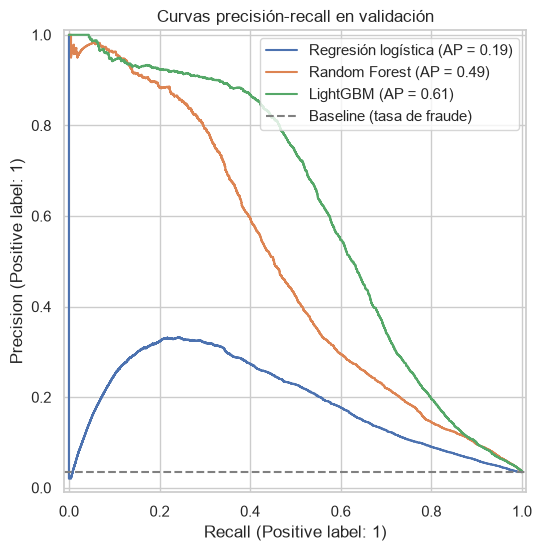

In [22]:
probas = {
    "Baseline": dummy_proba,
    "Regresión logística": logreg_proba,
    "Random Forest": rf_proba,
    "LightGBM": lgbm_proba,
}

results = pd.DataFrame({
    "PR-AUC": {name: average_precision_score(y_valid, p) for name, p in probas.items()},
    "ROC-AUC": {name: roc_auc_score(y_valid, p) for name, p in probas.items()},
}).round(3)

display(results)

fig, ax = plt.subplots(figsize=(8, 6))
for name, p in list(probas.items())[1:]:
    PrecisionRecallDisplay.from_predictions(y_valid, p, name=name, ax=ax)
ax.axhline(y_valid.mean(), color="grey", linestyle="--", label="Baseline (tasa de fraude)")
ax.set_title("Curvas precisión-recall en validación")
ax.legend()
plt.savefig(FIGURES_DIR / "pr_curves.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretación de las curvas:**

- **Baseline:** para detectar los fraudes, la única opción que tiene es marcarlas todas como fraude. Así tiene un recall de 1, porque pilla todos los fraudes, pero una precisión bajísima, de 0,034, porque ha marcado todas cuando el 96,6% no lo eran. Por eso es una línea plana en 0,034.

- **Regresión logística:** cuando encuentra el primer fraude, tiene una precisión de 1, porque a la primera acierta, pero un recall de prácticamente 0, porque quedan todos los demás por pillar. A medida que bajamos el umbral para pillar más fraude, empieza a marcar muchas transacciones como fraude cuando realmente no lo son. Al final acaba pillando todos, pero diciendo por el camino que muchas son fraude cuando no lo son, y por eso la curva va bajando.

- **Random Forest:** los primeros fraudes parece pillarlos bien, por eso empieza con una precisión de prácticamente el 100%. La curva empieza bastante plana: hasta pillar alrededor del 60% de los fraudes, todavía mantiene una precisión del 60%. Pero en el 40% restante cae en picado, de 0,6 hasta 0,034. Esos últimos fraudes son los difíciles, los que se parecen a transacciones legítimas.

- **LightGBM:** va por encima de Random Forest en casi todo el recorrido, es decir, pilla los mismos fraudes molestando a menos clientes. Con los fraudes fáciles la diferencia es pequeña: con un recall de 0,2, uno está alrededor de 0,9 y el otro de 0,95. Pero con un recall de 0,6 ya es mucho más notable: LightGBM está en torno a 0,55 y Random Forest en prácticamente 0,3. Es decir, con Random Forest molestaríamos a muchos más clientes para pillar el mismo fraude.

**Conclusión:** nos quedamos con LightGBM como modelo final. Es el mejor en las dos métricas, y su ventaja es mayor justo con los fraudes difíciles.

## Elección del umbral

El modelo nos da una probabilidad, pero un banco tiene que decidir si aprueba o bloquea cada transacción. Para elegir el umbral hay varios criterios, y cuál usar depende de cada banco:

- **Recall mínimo:** el banco se pone un objetivo, por ejemplo "pillar al menos el 50% del fraude", y se elige el umbral más alto que lo cumpla, que es el que menos clientes molesta.
- **Límite de alertas:** si hay un equipo de analistas que revisa las alertas a mano, se elige el umbral que no supere las alertas que pueden revisar al día.
- **Coste marginal:** comparar umbrales vecinos y ver cuántos clientes más molestamos por cada fraude extra que pillamos.
- **F1:** combina precisión y recall en un solo número, pero da el mismo peso a dejar escapar un fraude que a molestar a un cliente, y en la realidad casi nunca cuestan lo mismo.

Nosotros lo decidimos con el **coste en euros**, porque tenemos el importe de cada transacción:

- **El fraude que se escapa** se pierde entero. Si damos por legítima una compra fraudulenta de 100 €, hemos perdido esos 100 €, porque hay que devolvérselos al titular de la tarjeta.
- **Bloquear una compra legítima** no cuesta su importe completo, sino una fracción `p` de él: lo que cuesta que el cliente llame al servicio de atención, la venta que se pierde si no vuelve a intentar la compra y el riesgo de que se enfade y se vaya a otro banco. Si bloqueamos muchas, ese coste se acumula.

función de coste, Así, el coste de cada umbral es:

`coste = fraude que se escapa (€) + p × compras legítimas bloqueadas (€)`

Ese `p` depende de cada empresa y no lo tenemos, así que suponemos `p = 0,2` (bloquear una compra de 100 € cuesta 20 €) y comprobamos si el umbral elegido cambia con otros valores (0,1 y 0,5). Si sale el mismo, la decisión no depende de haber acertado con `p`.

In [23]:
rows = []
for threshold in [0.3, 0.5, 0.7, 0.8, 0.9, 0.95]:
    pred = (lgbm_proba >= threshold).astype(int)
    caught = ((pred == 1) & (y_valid == 1)).sum()
    blocked = ((pred == 1) & (y_valid == 0)).sum()
    rows.append({
        "umbral": threshold,
        "recall": recall_score(y_valid, pred),
        "precisión": precision_score(y_valid, pred),
        "fraudes pillados": caught,
        "fraudes que se escapan": y_valid.sum() - caught,
        "clientes molestados": blocked,
    })

thresholds = pd.DataFrame(rows).round(3)
thresholds

,umbral,recall,precisión,fraudes pillados,fraudes que se escapan,clientes molestados
0,0.30,0.583,0.579,2371,1693,1725
1,0.50,0.517,0.718,2102,1962,827
2,0.70,0.453,0.814,1843,2221,420
3,0.80,0.418,0.854,1698,2366,290
4,0.90,0.356,0.885,1446,2618,188
5,0.95,0.309,0.902,1256,2808,136


In [27]:
amt = X_valid["TransactionAmt"]
BLOCK_COST = 0.2

rows = []
for threshold in [0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 0.8, 0.9]:
    pred = (lgbm_proba >= threshold).astype(int)
    fraud_missed = amt[(pred == 0) & (y_valid == 1)].sum()
    legit_blocked = amt[(pred == 1) & (y_valid == 0)].sum()
    rows.append({
        "umbral": threshold,
        "fraude que se escapa (€)": fraud_missed,
        "compras legítimas bloqueadas (€)": legit_blocked,
        "coste total (€)": fraud_missed + BLOCK_COST * legit_blocked,
    })
costs = pd.DataFrame(rows).round(2)
costs

,umbral,fraude que se escapa (€),compras legítimas bloqueadas (€),coste total (€)
0,0.05,151308.40625,1.643689e+06,480046.12500
1,0.10,204978.06250,9.376118e+05,392500.43750
2,0.20,255484.65625,4.875176e+05,352988.18750
3,0.30,297781.15625,2.997499e+05,357731.15625
4,0.50,342542.75000,1.279709e+05,368136.90625
5,0.70,394423.09375,5.195558e+04,404814.18750
6,0.80,415649.62500,3.023245e+04,421696.12500
7,0.90,454458.56250,1.386534e+04,457231.62500


**Elección del umbral:**

El coste total tiene forma de U: con un umbral muy bajo bloqueamos tantas compras legítimas que ese coste se dispara, y con uno muy alto se nos escapa demasiado fraude. Con p = 0,2, el mínimo está en 0,2 (352.988 €).

Pero el mejor umbral depende mucho de cuánto cueste molestar a un cliente. Con p = 0,1 el mínimo está en 0,1; con p = 0,2, en 0,2; y con p = 0,5, en 0,5. Cuanto más caro es molestar, más alto conviene el umbral.

**Elegimos el umbral 0,5.** Molestar a un cliente no solo cuesta la llamada o la venta perdida: también puede enfadarse e irse del banco, y ese coste es difícil de medir. Por eso creemos que el 20% se queda corto. Con 0,5 el coste es solo 10.406 € más alto que con 0,3 (con p = 0,2), pero bloqueamos unos 172.000 € menos de compras legítimas y molestamos a menos de la mitad de clientes (827 frente a 1.725). Además, si molestar cuesta la mitad de la compra (p = 0,5), el 0,5 pasa a ser el umbral más barato.

### Matriz de confusión con el umbral elegido

Con el umbral 0,5, vemos cuántas transacciones caen en cada caso: fraudes pillados, fraudes que se escapan, clientes molestados y legítimas aprobadas. También calculamos cuánto nos costaría no tener modelo, es decir, dejar pasar todo el fraude, para saber cuánto dinero nos ahorra LightGBM.

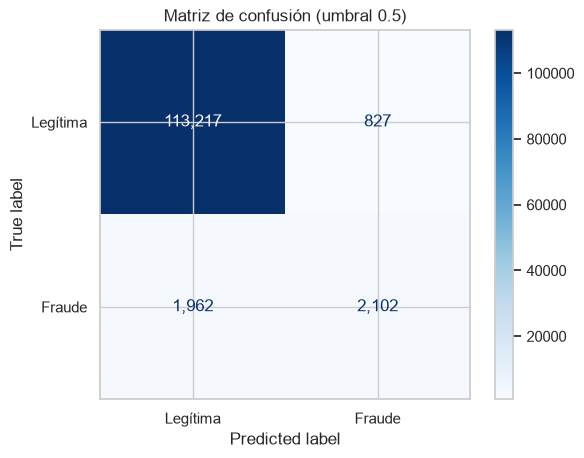

Coste sin modelo:   609,934 €
Coste con LightGBM: 368,137 €
Ahorro:             241,797 € (40%)


In [31]:
THRESHOLD = 0.5
final_pred = (lgbm_proba >= THRESHOLD).astype(int)

ConfusionMatrixDisplay.from_predictions(
    y_valid, final_pred,
    display_labels=["Legítima", "Fraude"],
    values_format=",d", cmap="Blues",
)
plt.title(f"Matriz de confusión (umbral {THRESHOLD})")
plt.savefig(FIGURES_DIR / "confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

no_model_cost = amt[y_valid == 1].sum()
model_cost = amt[(final_pred == 0) & (y_valid == 1)].sum() + 0.2 * amt[(final_pred == 1) & (y_valid == 0)].sum()

print(f"Coste sin modelo:   {no_model_cost:,.0f} €")
print(f"Coste con LightGBM: {model_cost:,.0f} €")
print(f"Ahorro:             {no_model_cost - model_cost:,.0f} € ({1 - model_cost / no_model_cost:.0%})")

**Interpretación:**

Sin modelo, todo el fraude se escaparía: 609.934 € en el periodo de validación. Con LightGBM y el umbral 0,5, el coste baja a 368.137 €: paramos fraude por valor de 267.391 € y molestar a 827 clientes nos cuesta unos 25.594 €. El ahorro neto es de 241.797 €, un 40%.

Por número pillamos el 52% de los fraudes, pero por importe solo el 44%: los fraudes que se nos escapan suelen ser de importe más alto.

## Importancia de variables

Vamos a ver en qué variables se fija más LightGBM para detectar el fraude, y si las que creamos en el feature engineering le sirven de algo. Usamos la importancia por ganancia (`gain`): cuánto mejora el modelo, en total, gracias a los cortes que hace con cada variable.

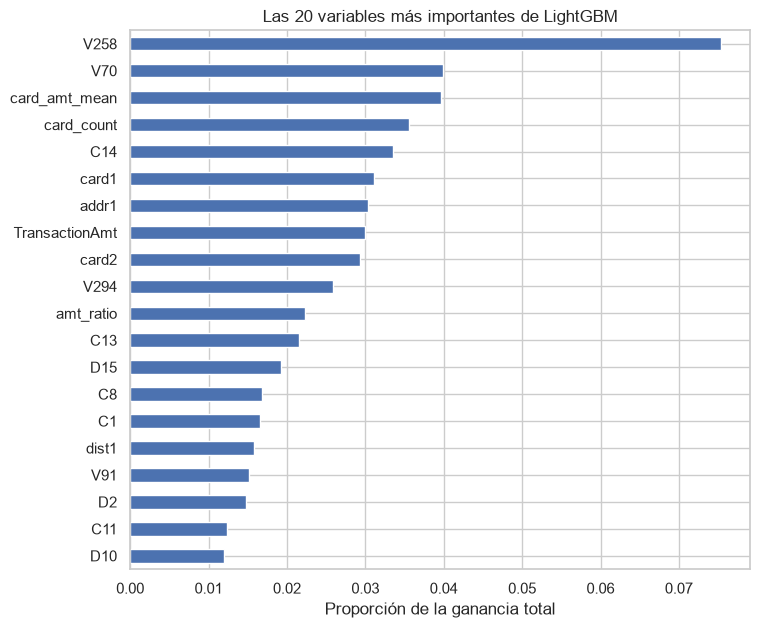

,posición,importancia
card_amt_mean,3,0.0397
card_count,4,0.0356
amt_ratio,11,0.0223
hour,23,0.0105
amt_cents,27,0.0085
weekday,38,0.0065
risk_score,56,0.0033
has_r_email,413,0.0001
has_addr,504,0.0000
has_identity,528,0.0000


In [33]:
importance = pd.Series(
    lgbm.booster_.feature_importance(importance_type="gain"),
    index=X_train.columns,
).sort_values(ascending=False)
importance = importance / importance.sum()

importance.head(20).sort_values().plot(kind="barh", figsize=(8, 7))
plt.title("Las 20 variables más importantes de LightGBM")
plt.xlabel("Proporción de la ganancia total")
plt.savefig(FIGURES_DIR / "feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

created = ["has_identity", "has_addr", "has_r_email", "hour", "weekday", "amt_cents",
           "card_count", "card_amt_mean", "amt_ratio", "risk_score"]
ranking = importance.rank(ascending=False).astype(int)
pd.DataFrame({"posición": ranking[created], "importancia": importance[created].round(4)}).sort_values("posición")

**Interpretación:**

Las variables que más han servido son los agregados por tarjeta: `card_amt_mean` (puesto 3) y `card_count` (puesto 4) están entre las cuatro más importantes de más de 500 columnas, y `amt_ratio` en el puesto 11. Comparar cada transacción con lo que suele hacer su tarjeta es de lo que más le ayuda al modelo. También aportan `hour` (puesto 23) y `amt_cents` (puesto 27), lo que confirma lo que vimos de la madrugada y de los céntimos raros.

`weekday` aporta poco (puesto 38), pero no es inútil, así que la mantenemos.

Los indicadores `has_identity`, `has_addr` y `has_r_email` casi no aportan nada. No es que los nulos no tengan información, porque en el EDA vimos que sí, sino que LightGBM ya trata los nulos por sí solo en las columnas originales, así que estos indicadores le resultan redundantes. Lo mismo pasa con `risk_score` (puesto 56): LightGBM aprende por sí mismo a combinar las condiciones de riesgo, aunque la variable sigue siendo útil para interpretar el resultado.

## Conclusiones

Hemos utilizado cuatro modelos para predecir el fraude:

| Modelo | PR-AUC | ROC-AUC |
|---|---|---|
| Baseline | 0,034 | 0,500 |
| Regresión logística | 0,190 | 0,835 |
| Random Forest | 0,493 | 0,903 |
| **LightGBM** | **0,611** | **0,917** |

**El mejor es LightGBM**, porque es el que tiene la PR-AUC más alta: consigue el mejor equilibrio entre pillar fraude y no molestar a muchos clientes. Le sigue Random Forest, aunque LightGBM lo supera en un 24%.

**¿Por qué la regresión logística queda tan lejos?** Porque, al ser lineal, cada variable solo puede subir o bajar el riesgo, siempre en la misma dirección, y en nuestros datos hay muchas relaciones no lineales:

- **El importe** (`TransactionAmt`) tiene forma de U: hay más fraude en los importes muy bajos y en los muy altos.
- **La hora** tiene un pico en la madrugada real y un mínimo a mediodía.
- **`amt_ratio`** sube hasta que la compra es de 2 a 5 veces lo habitual de la tarjeta, y luego vuelve a bajar.
- **Los céntimos** no tienen orden: `,95` es muy seguro, `,00` está en la media y los céntimos irregulares son muy peligrosos.

Además, hay interacciones: en el EDA vimos que el efecto del importe depende de si la transacción tiene datos de identidad. Los árboles captan todo esto con sus cortes, y la logística no.

**Umbral elegido: 0,5.** Lo elegimos con una función de coste: el fraude que se escapa se pierde entero, y bloquear una compra legítima cuesta una parte `p` de su importe. El `p` es inventado, porque no tenemos los datos reales, pero cualquier banco con un analista de riesgos nos los podría dar. Elegimos el 0,5 porque es el que menos cuesta si molestar a un cliente tiene un coste alto, por el riesgo de que se vaya del banco. Con este umbral:

- Pillamos **2.102 fraudes**, el 52%.
- Molestamos a **827 clientes legítimos**, unos 0,4 por cada fraude que pillamos.
- Pasamos de perder **609.934 €** sin modelo a un coste de **368.137 €**: le **ahorramos al banco 241.797 €, un 40%**, en el periodo de validación (alrededor de mes y medio de transacciones).

**Variables más útiles:** las que creamos en el feature engineering comparando cada transacción con su tarjeta han sido de las más importantes del modelo: `card_amt_mean` (el importe medio de la tarjeta) en el puesto 3, `card_count` en el 4 y `amt_ratio` en el 11, de más de 500 columnas. En cambio, `risk_score` y los indicadores de nulos (`has_`) no han sido muy útiles: LightGBM ya trata los nulos y aprende las combinaciones por sí solo, así que le resultan redundantes.

**Limitaciones:**

- Se nos escapa casi la mitad del fraude (1.962 de 4.064), y sobre todo el de mayor importe: por número pillamos el 52%, pero por importe solo el 44%.
- Usamos la validación para el early stopping y para elegir el umbral, así que los resultados son ligeramente optimistas.
- El ahorro depende de `p`, que es una suposición nuestra.

**Próximos pasos:**

- Crear un identificador de cliente combinando `card1`, `addr1` y `D1`, como hicieron los ganadores de la competición, para comparar cada transacción con el comportamiento habitual del cliente y no solo de la tarjeta.
- Usar SHAP para explicar por qué el modelo marca cada transacción concreta como sospechosa.